#Copernicus data import and processing for the 2022 Environmental Oder Disaster

### Used imports

In [2]:
from scripts.copernicus_api import get_access_token, search_tile, download_product
from scripts.file_aux import process_resolution_for_aoi, sample_points, extract_bands_from_zip
from scripts.plot_aux import plot_background_map
from scripts.index_aux import calculate_ndci
from pathlib import Path
import os
import re
from zipfile import ZipFile
import shutil
import geopandas as gpd
import numpy as np
from matplotlib import pyplot as plt
from shapely.ops import substring
from matplotlib.colors import Normalize

### Constant values and settings

In [3]:
MAP_CRS = "EPSG:3035"

plt.style.use('dark_background')

### Area of interest

![alt text](figures/AOIs.png "Area of interest around Oder with tiles found by Copernicus. Some corner cases have been discarded.")

Area of interest around Oder with tiles found by Copernicus. Some corner cases have been discarded. The tiles are separated into two groups: lower Oder below Ścinawa and upper Oder up to Gliwice (images include farther parts).

We are mainly interested in three areas:
 - middle section of Oder around Krosno Odrzańskie with registered cholorphyll peak [(Stelzer, 2022)](https://www.igb-berlin.de/en/news/new-analysis-satellite-data-confirm-massive-algal-bloom-oder-river) (tile `T33UWT`),
 - Oder mouth around Świnoujście and Szczecin Lagoon (tile `T33UVV`),
 - Pomeranian Bay (tile `T33UVA`).

The chosen tiles are:
 - `T33UVA` - Pomeranian Bay (northernmost)
 - `T33UVV` - Szczecin and Szczecin Lagoon (right south of `T33UVA`)
 - `T33UVU` - Frankfurt to Gryfino segment (right south of `T33UVV`)
 - `T33UVT` - Lusatia, Krosno to Frankfurt segment (right south of `T33UVU`)
 - `T33UWT` - Ścinawa to Krosno segment (right east of `T33UVT`)
 - `T33UXS` - Krapkowice to Ścinawa segment (right south-east to `T33UWT`)
 - `T33UYR` - Upper Silesia, source to Krapkowice segment (right south-east to `T33UXS`)

In [4]:
lower_Oder_tiles = ["T33UVV", "T33UVU", "T33UVA", "T33UVT", "T33UWT"]
upper_Oder_tiles = ["T33UWS", "T33UYR", "T33UXS"]
# tiles = ["T33UVT", "T33UWT"] # for testing only a single tile is taken
tiles = lower_Oder_tiles + upper_Oder_tiles

To limit the space usage, the imagery is split into 18 segments shown in the map below. The segments are:
 - `Pomeranian_Bay` - sea area right outside of the Oder rivermouth,
 - `Usedom_Wolin` - delta area of the Oder rivermouth including the major islands of Usedom and Wolin,
 - `Szczecin_Lagoon` - upper rivermouth area between Oder proper and the delta archipelago,
 - `Szczecin` - metropolitan area of Szczecin and the lower reaches of the Lower Oder Landscape Park up to Gryfino,
 - `Lower_Oder` - the remainder of the Lower Oder Landscape Park,
 - `Oder_1` - area of Nationalpark Unteres Oder,
 - `Oder_2` - Cedynia bend,
 - `Oder_3` - Kostrzyn-Cedynia segment,
 - `Oder_4` - Frankfurt-Kostrzyn segment,
 - `Oder_5` - Eisenhüttenstadt segment,
 - `Oder_6` - Zielona Góra-Krzesin segment,
 - `Oder_7` - Nowa Sól-Zielona Góra bend segment,
 - `Oder_8` - Głogów segment,
 - `Oder_9` - Legnica-Góra segment,
 - `Oder_10` - Brzeg Dolny segment,
 - `Oder_11` - Wrocław segment,
 - `Oder_12` - Brzeg semgent,
 - `Oder_13` - Kędzierzyn Koźle-Opole segment

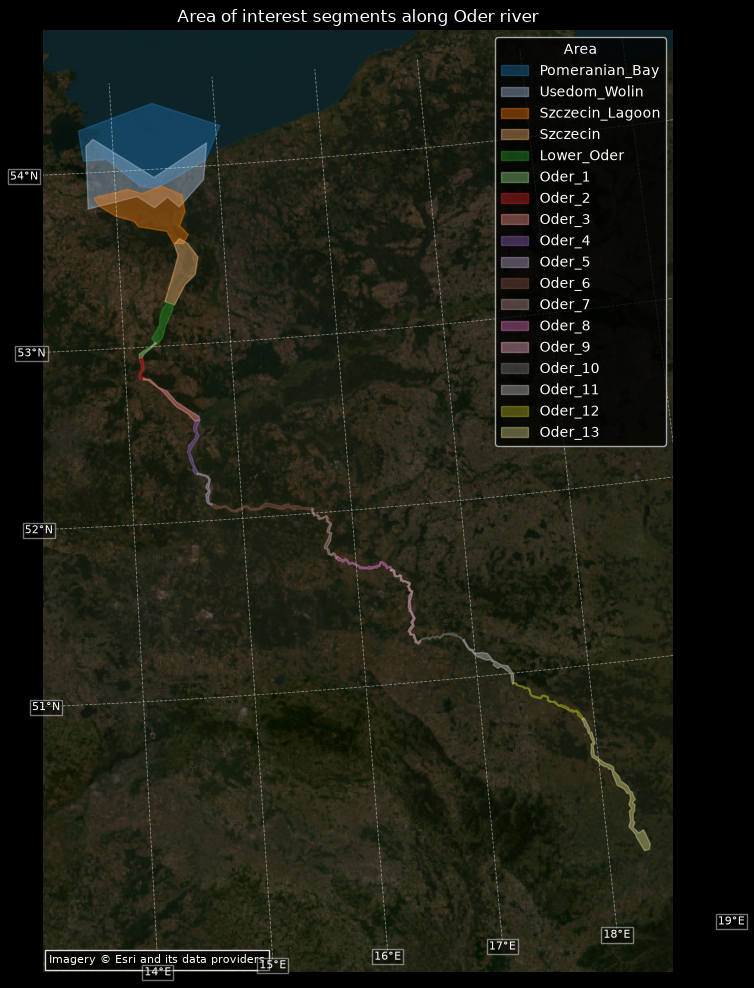

In [5]:
aoi_polygons = gpd.read_file("objects/small_AOI.geojson").to_crs(MAP_CRS)
aoi_names = aoi_polygons["NAME"]

cmap = plt.colormaps["tab20"]
colour_for_name = {
    name: cmap(i % cmap.N)
    for i, name in enumerate(aoi_names)
}

fig, ax = plot_background_map("Area of interest segments along Oder river", (13.0, 49.5, 19.5, 54.5), MAP_CRS)

for name in aoi_names:
    group = aoi_polygons.loc[aoi_names == name]

    group.plot(
        ax=ax,
        facecolor=colour_for_name[name],
        edgecolor=colour_for_name[name],
        alpha=0.40,
        linewidth=1.0,
        label=name,
    )

ax.legend(
    title="Area",
    loc="upper right"
)

plt.show()

The values are sampled along the Oder river centreline. The distances are measured from the rivermouth end.

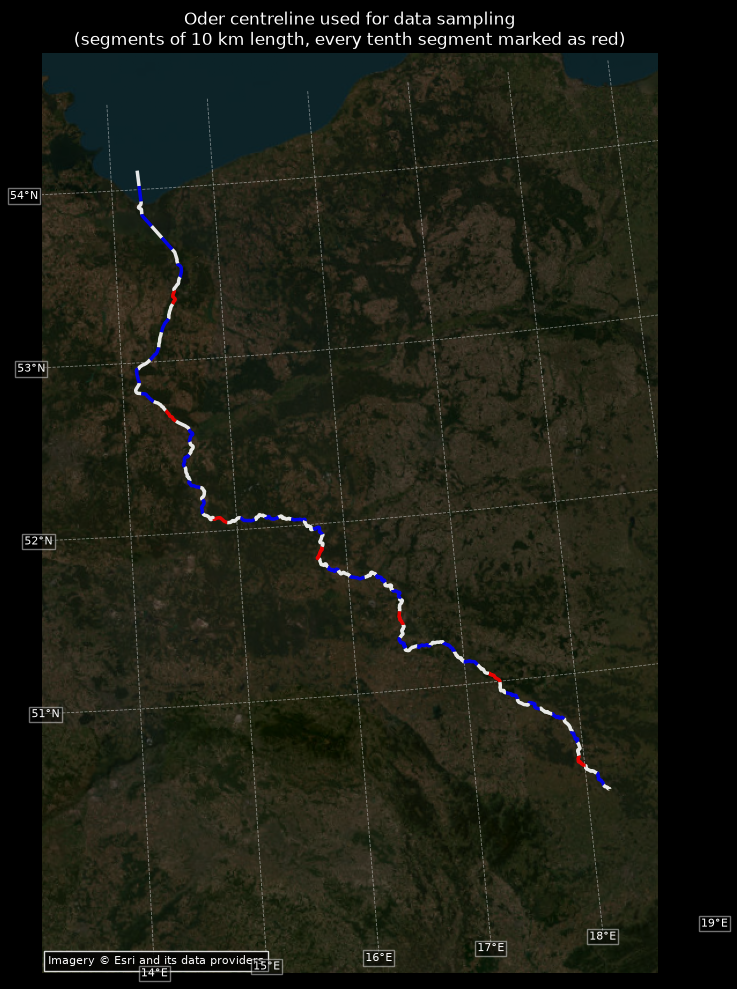

In [6]:
oder_centreline = gpd.read_file("objects/Oder_centreline.geojson").to_crs(MAP_CRS)
oder_geometry = oder_centreline.geometry.iloc[0]
segment_length = 10_000
colours = ["white", "blue"] * 4 + ["white", "red"]

fig, ax = plot_background_map(
    title="Oder centreline used for data sampling\n(segments of 10 km length, every tenth segment marked as red)",
    limits=(13.0, 49.5, 19.5, 54.5),
    target_crs=MAP_CRS
)

for i, start_distance in enumerate(np.arange(0, oder_geometry.length, segment_length)):
    end_distance = min(start_distance + segment_length, oder_geometry.length)

    segment = gpd.GeoSeries([
        substring(
            oder_geometry,
            start_distance,
            end_distance,
        )
    ], crs=oder_centreline.crs).to_crs(MAP_CRS)

    segment.plot(
        ax=ax,
        color=colours[i % len(colours)],
        linewidth=2.5,
        alpha=0.9,
    )

plt.show()

###Dates of interest

In [7]:
dates = [
    "2022-08-16",           # Little cloud cover over lower Oder around the peak
    #"2022-08-11",          # Little cloud cover from Ścinawa down
    #"2022-08-15",          # Little cloud cover for upper Oder (down to Wrocław)
    #"2022-08-26",          # Acceptable cloud cover for lower Oder
    #"2022-08-03",          # Almost clear skies for central Oder
    #"2022-08-04",          # Szczecin and the lagoon only
    #"2022-08-05",          # Little cloud cover for upper Oder (down to Wrocław)
]


In [8]:
download_dir = Path("./raw_data")

print("Requesting Copernicus access token...")
token = get_access_token()

all_products = []

for tile in tiles:

    print(f"\nSearching tile {tile}...")

    products = search_tile(tile, token, dates[0])

    if not products:
        print("  No matching Sentinel-2 L2A products found.")
        continue

    for product in products:

        print(
            f"  Found: {product['Name']}\n"
            f"  Sensing start: {product['ContentDate']['Start']}\n"
            f"  Product ID: {product['Id']}\n"
        )

        all_products.append(product)

# Remove duplicates, if any.
unique_products = {
    product["Id"]: product
    for product in all_products
}

print(f"\nTotal unique products found: {len(unique_products)}")

for product in unique_products.values():
    download_product(product, token, download_dir)

print("\nFinished.")

Requesting Copernicus access token...

Searching tile T33UVV...
  Found: S2A_MSIL2A_20220816T100611_N0510_R022_T33UVV_20240710T182750.SAFE
  Sensing start: 2022-08-16T10:06:11.024000Z
  Product ID: 70dab37a-1a93-4c08-a2a2-11e696056757


Searching tile T33UVU...
  Found: S2A_MSIL2A_20220816T100611_N0510_R022_T33UVU_20240710T182750.SAFE
  Sensing start: 2022-08-16T10:06:11.024000Z
  Product ID: 59e14319-facb-4cb1-8a91-d2b9c7ad0063


Searching tile T33UVA...
  Found: S2A_MSIL2A_20220816T100611_N0510_R022_T33UVA_20240710T182750.SAFE
  Sensing start: 2022-08-16T10:06:11.024000Z
  Product ID: c39598f2-b677-4e81-974a-f4bd1920f45b


Searching tile T33UVT...
  Found: S2A_MSIL2A_20220816T100611_N0510_R022_T33UVT_20240710T182750.SAFE
  Sensing start: 2022-08-16T10:06:11.024000Z
  Product ID: d50063c9-80ad-4efb-a17d-b8ff057e436c


Searching tile T33UWT...
  Found: S2A_MSIL2A_20220816T100611_N0510_R022_T33UWT_20240710T182750.SAFE
  Sensing start: 2022-08-16T10:06:11.024000Z
  Product ID: fdc0c5aa-7

### Extract bands of interest

In [9]:
files = os.listdir("raw_data")

zips = []
full_bands = ["B02_10m", "B03_10m", "B04_10m", "B05_20m", "B08_10m", "B11_20m", "SCL_20m"]
bands10 = ["B02", "B03", "B04", "B08"]
bands20 = ["B05", "B11", "SCL"]

for file in files:
    match = re.match(
        r"S2A_MSIL2A_(\d+)T(?:\d+)_(?:N\d+)_(?:R\d+)_(T\d\d\w\w\w)_(?:\d+T\d+)\.SAFE\.zip",
        file)
    if match:
        zips.append((match.group(1), match.group(2), file))

for (date, tile, filename) in zips:
    extract_bands_from_zip(date, tile, filename, bands10, bands20)


Extracted directory already exists for 20220816_T33UVV. Skipping extraction.
Extracted directory already exists for 20220816_T33UVA. Skipping extraction.
Extracted directory already exists for 20220816_T33UXS. Skipping extraction.
Extracted directory already exists for 20220816_T33UWT. Skipping extraction.
Extracted directory already exists for 20220816_T33UVU. Skipping extraction.
Extracted directory already exists for 20220816_T33UWS. Skipping extraction.
Extracted directory already exists for 20220816_T33UVT. Skipping extraction.


In [10]:
aoi_dir = Path("./raw_data/AOI/small_AOI.geojson")
band_dir = Path("./raw_data/extracted")

nodata_value = 0

data_dirs = os.listdir(band_dir)
data_by_dates = {}
band_files = {}
for dir in data_dirs:
    date = dir.split("_")[0]
    if date not in data_by_dates:
        data_by_dates[date] = []
        band_files[date] = {band.split("_")[0]: [] for band in full_bands}
    data_by_dates[date].append(dir)
    for band in full_bands:
        band_file = Path(band_dir) / dir / f"R{band[4:]}" / f"{band}.jp2"
        if band_file.exists():
            band_files[date][band.split("_")[0]].append(band_file)


### Save the masked areas of interest

In [11]:
masked_dir = Path("./local/masked/")
masked_dir.mkdir(parents=True, exist_ok=True)

aois = gpd.read_file("./objects/small_AOI.geojson")

aois["geometry"] = aois.geometry.buffer(0)
aois = aois.to_crs(MAP_CRS)

aois = aois.dissolve(by="NAME", as_index=False)

for date_text, tile_folders in sorted(data_by_dates.items()):
    for _, aoi_row in aois.iterrows():

        aoi_name = aoi_row["NAME"]
        aoi_geometry = aoi_row.geometry

        process_resolution_for_aoi(
            date_text=date_text,
            band_files=band_files,
            aoi_name=aoi_name,
            aoi_geometry=aoi_geometry,
            resolution_label="10m",
            bands=bands10,
            output_root=masked_dir,
            target_crs=MAP_CRS
        )

        process_resolution_for_aoi(
            date_text=date_text,
            band_files=band_files,
            aoi_name=aoi_name,
            aoi_geometry=aoi_geometry,
            resolution_label="20m",
            bands=bands20,
            output_root=masked_dir,
            target_crs=MAP_CRS
        )

Stack file already exists for AOI Lower_Oder and resolution 10m. Skipping processing.
Stack file already exists for AOI Lower_Oder and resolution 20m. Skipping processing.
Stack file already exists for AOI Oder_1 and resolution 10m. Skipping processing.
Stack file already exists for AOI Oder_1 and resolution 20m. Skipping processing.
Stack file already exists for AOI Oder_2 and resolution 10m. Skipping processing.
Stack file already exists for AOI Oder_2 and resolution 20m. Skipping processing.
Stack file already exists for AOI Oder_3 and resolution 10m. Skipping processing.
Stack file already exists for AOI Oder_3 and resolution 20m. Skipping processing.
Stack file already exists for AOI Oder_4 and resolution 10m. Skipping processing.
Stack file already exists for AOI Oder_4 and resolution 20m. Skipping processing.
Stack file already exists for AOI Oder_5 and resolution 10m. Skipping processing.
Stack file already exists for AOI Oder_5 and resolution 20m. Skipping processing.
Stack fi

### Sample river profiles for all dates

In [12]:
masked_dirs = os.listdir(masked_dir)
profiles = {}
SCL_WATER_CLASS = 6
for dir in masked_dirs:
    date = dir.split("/")[-1]
    for resolution in ["10m", "20m"]:
        profile = sample_points(
            data_dir=masked_dir / dir,
            line_geometry=oder_geometry,
            sample_spacing=10,
            sample_class=SCL_WATER_CLASS
        )
        calculate_ndci(profile=profile, median_window=51)
        profiles[date] = profile

## Data presentation

### NDCI

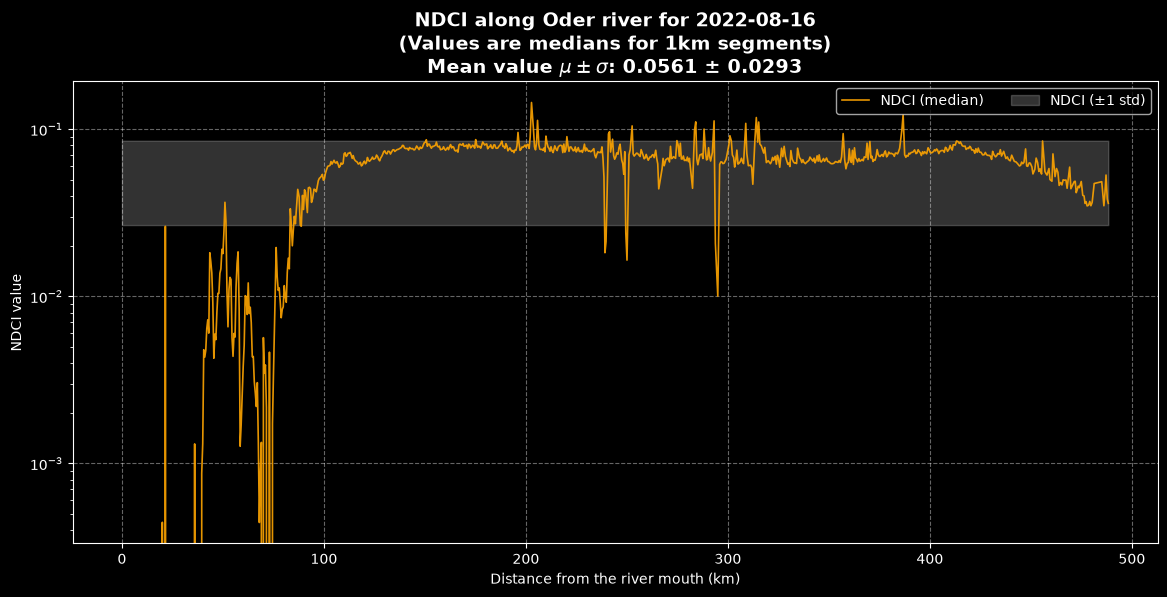

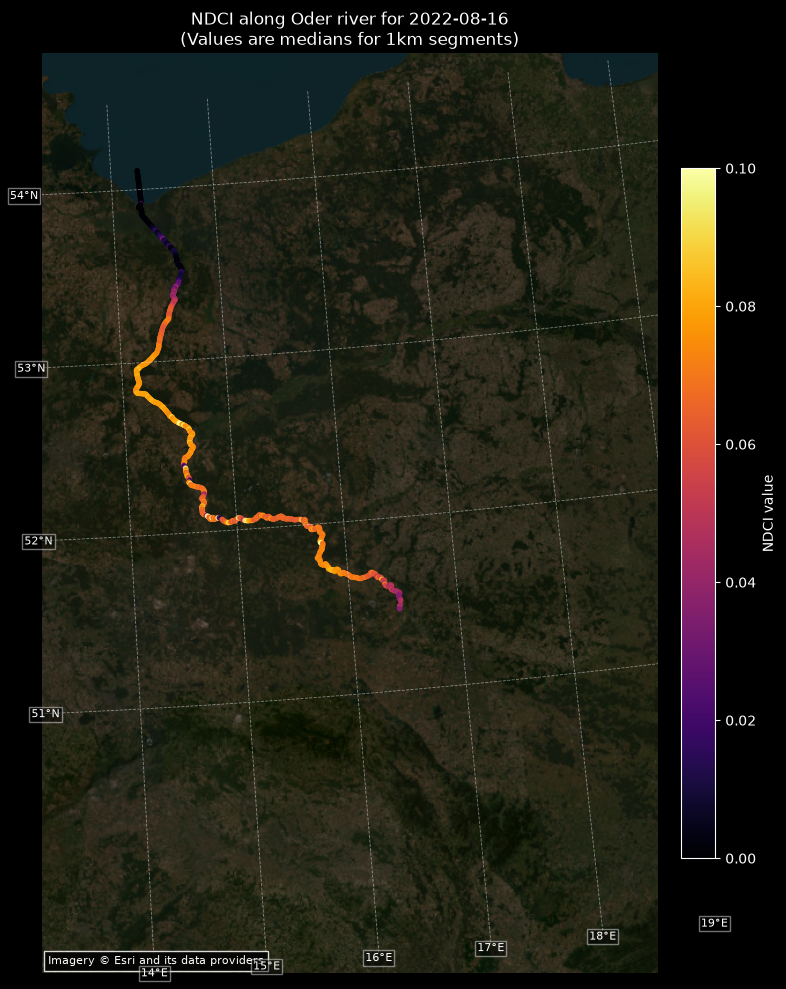

In [13]:
for date in profiles:
    profile = profiles[date][::50]
    year, month, day = date[0:4], date[4:6], date[6:8]

    fig, ax = plt.subplots(figsize=(14, 6))

    ndci_mean = np.mean(profile["local median NDCI"])
    ndci_std = np.std(profile["local median NDCI"])

    ax.plot(
        profile["distance_km"],
        profile["local median NDCI"],
        label="NDCI (median)",
        color="orange",
        linewidth=1.2,
        alpha=0.9
    )

    ax.fill_between(
        profile["distance_km"],
        ndci_mean - ndci_std,
        ndci_mean + ndci_std,
        color="white",
        alpha=0.2,
        label="NDCI (±1 std)"
    )

    ax.set_title(
        "NDCI along Oder river for " + f"{year}-{month}-{day}\n(Values are medians for 1km segments)" +
        "\nMean value $\\mu\\pm\\sigma$: " + f"{ndci_mean:.4f} ± {ndci_std:.4f}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Distance from the river mouth (km)")
    ax.set_ylabel("NDCI value")

    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(ncols=2)
    ax.set_yscale('log')

    plt.show()

    fig, ax = plot_background_map(
        title=f"NDCI along Oder river for {year}-{month}-{day}\n(Values are medians for 1km segments)",
        limits=(13.0, 49.5, 19.5, 54.5),
        target_crs=MAP_CRS
    )

    samples_gdf = gpd.GeoDataFrame(
        profile["local median NDCI"],
        geometry=gpd.points_from_xy(profile["x"], profile["y"]),
        crs=MAP_CRS,
    )

    cmap = plt.colormaps["inferno"]
    norm = Normalize(vmin=0, vmax=0.1)

    samples_gdf.plot(
        ax=ax,
        column="local median NDCI",
        cmap=cmap,
        norm=norm,
        markersize=15,
        marker="o",
        edgecolor="none",
        alpha=0.95,
    )

    colourbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        pad=0.02,
        shrink=0.75,
    )

    colourbar.set_label("NDCI value")
    plt.show()


### Spectral distribution depending on NDCI

In [ ]:
for date in profiles:
    profile = profiles[date]
    bucket_limits = [[0, 0.02], [0.02, 0.05], [0.05, 1.1]]
    ndci = profile["NDCI"]
    display(profile.columns)
    buckets = [profile[(profile[ndci>=low])&(ndci<high)] for low, high in bucket_limits]


Index(['distance_m', 'distance_km', 'B02 Blue', 'B03 Green', 'B04 Red',
       'B08 NIR', 'B05 RedEdge1', 'B11 SWIR1', 'SCL SceneClassification', 'x',
       'y', 'NDCI', 'local median NDCI'],
      dtype='str')